In [1]:
import seaborn as sb
import numpy as np
import random
import math
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import functools as ft
import statistics
import scipy as sc
import pingouin as ping
import hyppo as hyp

In [ ]:
1. Рассмотрим величину с плотностью f(x) = c/(|x| ln2

|x|) на отрезке [−1/e, 1/e]. Что говорит теория о

сходимости суммы таких величин?
Проиллюстрируем это на практике – сгенерируем выборку из сумм n таких величин при различных n.
Можем ли мы увидеть на гистограмме особенность плотности суммы?

c = 1/2

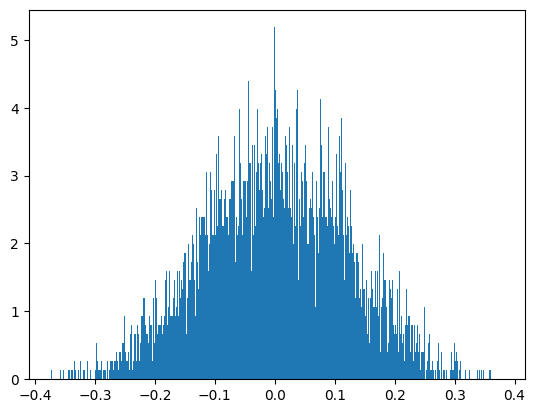

In [57]:
def f(x):
    if np.abs(x)<= 1/np.e:
        return 1 / (2*np.abs(x)* (np.log(np.abs(x))**2)) 

def F_rev(y):
    if np.abs(y)<= 0.00001:
        return 0
    if y >= 0 and y < 1/2:
        return -(np.e ** (1/(2*y - 1)))
    if y >0 and y <= 1:
        return np.e ** (1/(-2*y + 1)) 
    
def generator(m, n, F_rev):
    x = np.zeros(m)
    for k in range(n):
        r = np.random.uniform(0,1, size= m)
        x = x + np.array([F_rev(y) for y in r])
    return x / 2**(n/2)

m = 10000 # размер выборки
n = 3 # сколько складываю
x = [0]*n
for k in range(n):
    x = generator(m, n, F_rev)
plt.hist(x, density = "true", bins = 1000)
plt.show()

In [ ]:
2. Пусть Xi – н.о.р. с распределением F размера n. Найти вероятность того, что выборка имеет сумму
Sn, большую 2nEF X для различных n, используя явный вид функции распределения из Python. Для

выборок какого размера приближение из центральной предельной теоремы отклоняется вдвое от ре-
альной вероятности в относительном смысле? Как это отражается на p-value при применении критерия

Стьюдента с нормальной аппроксимацией?
Задача на бонус по дополнительным главам: получить асимптотику из теоремы Петрова о больших
уклонениях и сравнить результат с ней.
(a) F = exp(1);
(b) F = Bern(1/3).

In [11]:
c = 1.7
print("exp(1)")
for n in [1, 3, 5, 7, 10, 15, 100]:
    print("n = ", n)
    print("P(S_n > 2nEX):", 1-sc.stats.gamma.cdf(c*n, a = n, scale = 1))

print("\nbern(1/3)")
for n in [1, 3, 5, 7, 10, 15, 100]:
    print("n = ", n)
    print("P(S_n > 2nEX):", 1-sc.stats.binom.cdf(c*n/3, n, 1/3))

print("\nотклонения exp(1):")
for n in [1, 2, 3, 4, 5, 7, 10, 15,20,50]:
    print("n = ", n)
    print( ( 1-sc.stats.gamma.cdf(c*n, a = n, scale = 1)) / (1 - sc.stats.norm.cdf( (c*n-n)/np.sqrt(n) , 0, 1)) )

print("\nотклонения bern(1/3):")
for n in [1, 2, 3, 4, 5, 7, 10, 15,20,25,50,100]:
    print("n = ", n)
    print( ( 1-sc.stats.binom.cdf(c*n/3, n, 1/3)) / (1 - sc.stats.norm.cdf( (c*n-n)*(1/3)/np.sqrt(n*(2/9)) , 0, 1)) )

# становлюсь толерантнее тк вероятность для нормального больше и могу пропустить эффект

exp(1)
n =  1
P(S_n > 2nEX): 0.1826835240527347
n =  3
P(S_n > 2nEX): 0.11647834313417627
n =  5
P(S_n > 2nEX): 0.07436397981458043
n =  7
P(S_n > 2nEX): 0.04843502847143322
n =  10
P(S_n > 2nEX): 0.026124686804658293
n =  15
P(S_n > 2nEX): 0.009740824249336089
n =  100
P(S_n > 2nEX): 2.4300772505370105e-09

bern(1/3)
n =  1
P(S_n > 2nEX): 0.33333333333333326
n =  3
P(S_n > 2nEX): 0.2592592592592593
n =  5
P(S_n > 2nEX): 0.2098765432098766
n =  7
P(S_n > 2nEX): 0.17329675354366714
n =  10
P(S_n > 2nEX): 0.07656353198191335
n =  15
P(S_n > 2nEX): 0.030827922990928847
n =  100
P(S_n > 2nEX): 1.0207695225750157e-06

отклонения exp(1):
n =  1
0.7550039949153754
n =  2
0.9115017499558208
n =  3
1.0337747415611234
n =  4
1.1492016427264624
n =  5
1.2655020340619634
n =  7
1.5130721266805405
n =  10
1.9454878056266398
n =  15
2.904987751472233
n =  20
4.296568853952249
n =  50
42.76028739516983

отклонения bern(1/3):
n =  1
1.0741981769835913
n =  2
0.4592057943011818
n =  3
1.325228420503716

In [ ]:
3. * Сгенерируем траектории блужданий из а) стандартного экспоненциального распределения, б) распре-
деления Парето с параметром формы 3, в) величину с ф.р. 1 − e

−x/x3
, x ≥ 1. Отберем из траекторий
те, которые за n ходов оказываются выше 2nEX. Как выглядит их траектории, как они соотносятся с
“обычными траекториями” и какие соображения из теории больших уклонений они отражают?

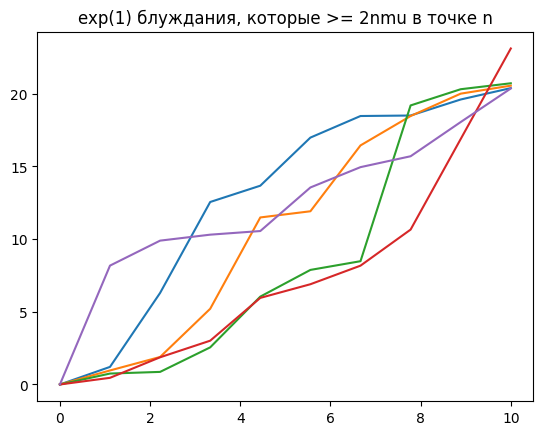

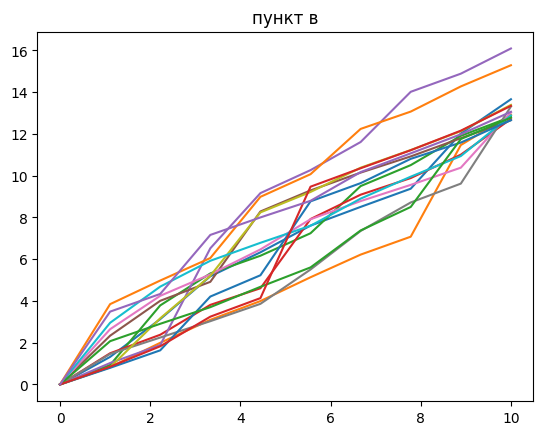

In [25]:
def gen_expon(n):
    s = [0]*n
    for k in range(1,n):
        s[k]=s[k-1] + sc.stats.expon.rvs(scale = 1)
    return s

def gen_pareto(n):
    s = [0]*n
    for k in range(1,n):
        s[k]=s[k-1] + sc.stats.pareto.rvs(b = 3)
    return s

def f(x):
    if x < 0 :
        return 0
    else:
        return (1 - np.exp(-x)/(x**3))

def gen_lol(f, n): 
    s = [0]*n
    r = np.random.uniform(0, 1, size = n)
    for j in range(1,n):
        s[j] = s[j-1] + sc.optimize.root_scalar(lambda x: f(x) - r[j], bracket=[-1, 10000], method='brentq').root
    return s
    
m = 4000 # сколько блужданий
n = 10 # длина блуждания


l = np.linspace(0,n,n)
for k in range(m):
    walk = gen_expon(n)
    if walk[n-1] >= 2*n:    
        plt.plot(l,walk)
    #plt.plot(l,walk)
#plt.title("exp(1) блуждания")
#plt.show()

plt.title("exp(1) блуждания, которые >= 2nmu в точке n")
plt.show()

m = 4000 # сколько блужданий
n = 10

l = np.linspace(0,n,n)
for k in range(m):
    walk = gen_lol(f, n)
    if walk[n-1] >= 2*n*( 1 - 1/np.e):     
        plt.plot(l,walk)
    #plt.plot(l,walk)
#plt.title("pareto(3) блуждания")
#plt.show()

plt.title("пункт в")
plt.show()



In [ ]:
Рассмотрим данные с функцией распределения F(x). Исследуйте последовательность нарастающих
частичных сумм Sn. Сходится ли Sn/
√
n? При каком α Sn/nα

сходится к невырожденному пределу?
Моделируйте соответствующие данные и постройте гистограмму предельного распределения.
Всего нужно сделать 2 пункта, которые определяются так. Если длина имени четная, то берете a, иначе
b, если длина фамилии четная, то берете c, иначе d.

Задача на бонус по дополнительным главам: сравните результат с теоремой об устойчивых распределе-
ниях.

(a) F(x) = 1 − 1/(2x
1/2
), x > 1, F(x) = e

x/2, x < 0 (это кусочно заданная функция).


(d) F(x) = 1 − 1/(2x
3/2
), x > 1, F(x) = 1/(2(−x)
3/2
), x < −1.

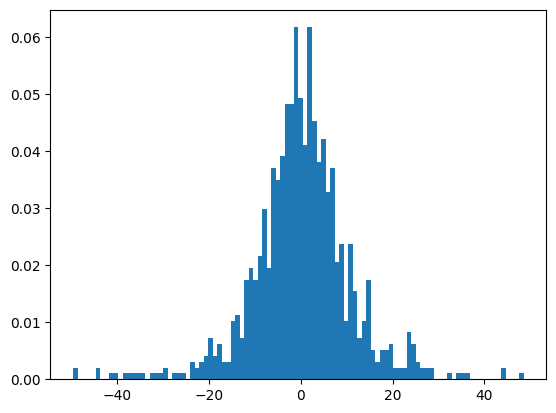

In [84]:
def gen(n, F_rev):
    y = np.random.uniform(0,1, size = n)
    x = [F_rev(r) for r in y]
    return x
    
def F_rev_a(y):
    if y<=1/2:
        return np.log(2*y)
    else:
        return (1/(2*(1-y)))**2

def F_rev_b(y):
    if y <=1/2:
        return -(1/(2*y))**(2/3)
    else:
        return (1/(2*(1-y)))**(2/3)

"""
arr = []
m = 1000
n = 50
for k in range(m):
    arr.append(np.sum(gen(n, F_rev_a)) / n**(2))
#print(arr)
plt.hist([x for x in arr if x>=-50 and x<+50], density = True, bins = 100)
plt.show()
"""

arr = []
m = 1000
n = 1000
for k in range(m):
    arr.append(np.sum(gen(n, F_rev_b)) / n**(1/2))
#print(arr)
plt.hist([x for x in arr if x>=-50 and x<+50], density = True, bins = 100)
plt.show()
